## Segundo paso: análisar los dataset .csv de (AAEC, ArGPT, MTC, AASS)

In [1]:
import pandas as pd
from tabulate import tabulate
import networkx as nx
import matplotlib.pyplot as plt
from networkx.drawing.nx_pydot import graphviz_layout
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import numpy as np
import seaborn as sns
from collections import defaultdict

In [10]:
result_path = "./../results/minimal_v5/"

In [3]:
def di_graph(text_id, G):

    pos = graphviz_layout(G, prog="dot")

    plt.figure(figsize=(14, 10))
    
    # Separar aristas por tipo de relación
    edges_support = [(u, v) for u, v, d in G.edges(data=True)
                    if d.get("label") == "support"]

    edges_attack = [(u, v) for u, v, d in G.edges(data=True)
                    if d.get("label") == "attack"]


    # Separar nodos por tipo y asignar color
    nodes_premise     = [n for n, d in G.nodes(data=True) if d.get("component") == "Premise"]
    nodes_majorclaim  = [n for n, d in G.nodes(data=True) if d.get("component") == "MajorClaim"]
    nodes_other       = [n for n in G.nodes() if n not in nodes_premise and n not in nodes_majorclaim]

    # Dibujar nodos por grupo
    nx.draw_networkx_nodes(G, pos, nodelist=nodes_premise,    node_color="lightgreen", node_size=1500)
    nx.draw_networkx_nodes(G, pos, nodelist=nodes_majorclaim, node_color="orange",     node_size=1500)
    nx.draw_networkx_nodes(G, pos, nodelist=nodes_other,      node_color="lightblue",  node_size=1500)


    # Dibujar etiquetas de nodos
    labels = {n: n.split("_")[-1] for n in G.nodes()}
    nx.draw_networkx_labels(G, pos, labels=labels, font_size=9)

    # Dibujar aristas con flechas visibles
    nx.draw_networkx_edges(G, pos, edgelist=edges_support,
                           edge_color="blue",
                           arrows=True,
                           arrowsize=20,
                           arrowstyle="-|>",
                           connectionstyle="arc3,rad=0.1",
                           min_source_margin=15,
                           min_target_margin=15)

    nx.draw_networkx_edges(G, pos, edgelist=edges_attack,
                           edge_color="red",
                           arrows=True,
                           arrowsize=20,
                           arrowstyle="-|>",
                           connectionstyle="arc3,rad=0.1",
                           min_source_margin=15,
                           min_target_margin=15)

    # Mostrar etiquetas de aristas
    edge_labels = nx.get_edge_attributes(G, "label")
    nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels,
                                font_size=9, rotate=False)

    # Leyenda
    legend = [
        Patch(color="lightgreen", label="Premise"),
        Patch(color="orange",     label="MajorClaim"),
        Patch(color="lightblue",  label="Other"),
    ]
    plt.legend(handles=legend, loc="upper left")
    
    plt.title(f"Grafo argumentativo: {text_id}", fontsize=14)
    plt.axis("off")
    plt.tight_layout()
    plt.show()

In [4]:
def plot_grafo(text_id, G):
    # Cor por nó
    color_nodo = {
        "MajorClaim" : "#e74c3c",   # Vermelho
        "Claim"      : "#3498db",   # Azul
        "Premise"    : "#2ecc71",   # Verde
    }
    node_colors = [
        color_nodo.get(G.nodes[n].get("component", ""), "#95a5a6")
        for n in G.nodes()
    ]

    colores_label = {
        "support" : "#27ae60",   # Verde oscuro
        "attack"  : "#c0392b",   # Vermelho oscuro
    }
    edge_colors   = [colores_label.get(d["label"], "gray") for _, _, d in G.edges(data=True)]
    
    plt.figure(figsize=(14, 10))
    pos = nx.spring_layout(G, seed=42, k=30, iterations=100)
    
    # Etiquetas de nodos con ID + tipo de componente
    node_labels = {
        n: f"{n}\n{G.nodes[n].get('component', '')}"
        for n in G.nodes()
    }

    nx.draw_networkx_nodes(G, pos, node_color=node_colors, node_size=2000)
    nx.draw_networkx_labels(G, pos, labels=node_labels, font_color="black", font_size=8, font_weight="bold")
    nx.draw_networkx_edges(
        G, pos,
        edge_color=edge_colors,
        arrows=True, arrowsize=25, arrowstyle="-|>",
        width=2, connectionstyle="arc3,rad=0.1",
        min_source_margin=30, min_target_margin=30,
    )
    
    edge_labels = nx.get_edge_attributes(G, "label")
    nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=7, font_color="darkgreen")
    
    leyenda = [
        Line2D([0], [0], color="green", linewidth=2, label="support"),
        Line2D([0], [0], color="red",   linewidth=2, label="attack"),
        Line2D([0], [0], color="gray",  linewidth=2, label="otros"),
    ]
    plt.legend(handles=leyenda, loc="upper left", fontsize=9)
    plt.title(f"Grafo argumentativo: {text_id}", fontsize=14)
    plt.axis("off")
    plt.tight_layout()
    plt.show()

### Dataset

In [28]:
# Cargar el DataFrame
df_cdcp = pd.read_pickle(result_path + "CDCP_Minimal_Grafo.pkl")
df_aaec = pd.read_pickle(result_path + "AAEC_Minimal_Grafo.pkl")
df_argpt = pd.read_pickle(result_path + "ArGPT_Minimal_Grafo.pkl")
df_mtc = pd.read_pickle(result_path + "MTC_Minimal_Grafo.pkl")
df_aasd = pd.read_pickle(result_path + "AASD_Minimal_Grafo.pkl")
df_glaucoma = pd.read_pickle(result_path + "AbstRCT_glaucoma_Minimal_Grafo.pkl")
df_mixed = pd.read_pickle(result_path + "AbstRCT_mixed_Minimal_Grafo.pkl")
df_neoplasm = pd.read_pickle(result_path + "AbstRCT_neoplasm_Minimal_Grafo.pkl")
# df_cdcp = pd.read_pickle(result_path + "CDCP_Minimal_Grafo_3class.pkl")
# df_aaec = pd.read_pickle(result_path + "AAEC_Minimal_Grafo_3class.pkl")
# df_argpt = pd.read_pickle(result_path + "ArGPT_Minimal_Grafo_3class.pkl")
# df_mtc = pd.read_pickle(result_path + "MTC_Minimal_Grafo_3class.pkl")
# df_aasd = pd.read_pickle(result_path + "AASD_Minimal_Grafo_3class.pkl")
# df_glaucoma = pd.read_pickle(result_path + "AbstRCT_glaucoma_Minimal_Grafo_3class.pkl")
# df_mixed = pd.read_pickle(result_path + "AbstRCT_mixed_Minimal_Grafo_3class.pkl")
# df_neoplasm = pd.read_pickle(result_path + "AbstRCT_neoplasm_Minimal_Grafo_3class.pkl")

In [137]:
df = df_aaec
df

,text_id,seg,info,graph,n_nodes,n_edges,n_isolates,n_comp,n_root,is_acyclic,is_connected,is_tree,is_arborescence,is_forest
0,AAEC_001,11,minimalist_labels labels_relation source...,"(AAEC_001_0, AAEC_001_1, AAEC_001_2, AAEC_001_...",11,12,0,1,2,True,True,False,False,False
1,AAEC_002,14,minimalist_labels labels_relation source...,"(AAEC_002_0, AAEC_002_1, AAEC_002_2, AAEC_002_...",14,15,0,1,2,True,True,False,False,False
2,AAEC_003,10,minimalist_labels labels_relation source_i...,"(AAEC_003_0, AAEC_003_1, AAEC_003_2, AAEC_003_...",10,10,0,1,2,True,True,False,False,False
3,AAEC_004,11,minimalist_labels labels_relation source...,"(AAEC_004_0, AAEC_004_1, AAEC_004_2, AAEC_004_...",11,12,0,1,2,True,True,False,False,False
4,AAEC_005,12,minimalist_labels labels_relation source...,"(AAEC_005_0, AAEC_005_1, AAEC_005_2, AAEC_005_...",12,14,0,1,2,True,True,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
397,AAEC_398,16,minimalist_labels labels_relation source...,"(AAEC_398_0, AAEC_398_1, AAEC_398_2, AAEC_398_...",16,15,0,1,1,True,True,True,True,True
398,AAEC_399,10,minimalist_labels labels_relation source_...,"(AAEC_399_0, AAEC_399_1, AAEC_399_2, AAEC_399_...",10,11,0,1,2,True,True,False,False,False
399,AAEC_400,10,minimalist_labels labels_relation source_i...,"(AAEC_400_0, AAEC_400_1, AAEC_400_2, AAEC_400_...",10,10,0,1,2,True,True,False,False,False
400,AAEC_401,10,minimalist_labels labels_relation source_i...,"(AAEC_401_0, AAEC_401_1, AAEC_401_2, AAEC_401_...",10,10,0,1,2,True,True,False,False,False


### Caracteristicas de grafo

In [147]:
# Numeros de nodos y componentes
label_columna = "n_isolates"
df_comparacion = df[
    (df[label_columna] != -1) 
    # &
    # (df["n_comp"] == 1)
    # &
    # (df["n_edges"] == 0)
]
conteo = df_comparacion.groupby(label_columna).size()
lista = conteo.to_dict()
print(df_comparacion.shape)
print("Lista de componentes: ",lista)
df_comparacion

(402, 14)
Lista de componentes:  {0: 400, 1: 2}


,text_id,seg,info,graph,n_nodes,n_edges,n_isolates,n_comp,n_root,is_acyclic,is_connected,is_tree,is_arborescence,is_forest
0,AAEC_001,11,minimalist_labels labels_relation source...,"(AAEC_001_0, AAEC_001_1, AAEC_001_2, AAEC_001_...",11,12,0,1,2,True,True,False,False,False
1,AAEC_002,14,minimalist_labels labels_relation source...,"(AAEC_002_0, AAEC_002_1, AAEC_002_2, AAEC_002_...",14,15,0,1,2,True,True,False,False,False
2,AAEC_003,10,minimalist_labels labels_relation source_i...,"(AAEC_003_0, AAEC_003_1, AAEC_003_2, AAEC_003_...",10,10,0,1,2,True,True,False,False,False
3,AAEC_004,11,minimalist_labels labels_relation source...,"(AAEC_004_0, AAEC_004_1, AAEC_004_2, AAEC_004_...",11,12,0,1,2,True,True,False,False,False
4,AAEC_005,12,minimalist_labels labels_relation source...,"(AAEC_005_0, AAEC_005_1, AAEC_005_2, AAEC_005_...",12,14,0,1,2,True,True,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
397,AAEC_398,16,minimalist_labels labels_relation source...,"(AAEC_398_0, AAEC_398_1, AAEC_398_2, AAEC_398_...",16,15,0,1,1,True,True,True,True,True
398,AAEC_399,10,minimalist_labels labels_relation source_...,"(AAEC_399_0, AAEC_399_1, AAEC_399_2, AAEC_399_...",10,11,0,1,2,True,True,False,False,False
399,AAEC_400,10,minimalist_labels labels_relation source_i...,"(AAEC_400_0, AAEC_400_1, AAEC_400_2, AAEC_400_...",10,10,0,1,2,True,True,False,False,False
400,AAEC_401,10,minimalist_labels labels_relation source_i...,"(AAEC_401_0, AAEC_401_1, AAEC_401_2, AAEC_401_...",10,10,0,1,2,True,True,False,False,False


In [146]:
id_text_busca = "CDCP_00198"
columna = "text_id"
result = df[df[columna] == id_text_busca]
result_info = result.iloc[0]

IndexError: single positional indexer is out-of-bounds

In [134]:
result

,text_id,seg,info,graph,n_nodes,n_edges,n_isolates,n_comp,n_root,is_acyclic,is_connected,is_tree,is_arborescence,is_forest
5,CDCP_00199,2,"Empty DataFrame Columns: [minimalist_labels, l...","(CDCP_00199_0, CDCP_00199_1)",2,0,2,2,2,True,False,False,False,True


In [135]:
result_info["info"]

,minimalist_labels,labels_relation,source_id,label_component_source,minimal_label_component_source,target_id,label_component_target,minimal_label_component_target


/tmp/ipykernel_76568/2138295617.py:3: DeprecationWarning: nx.nx_pydot.graphviz_layout depends on the pydot package, which has known issues and is not actively maintained. Consider using nx.nx_agraph.graphviz_layout instead.

See https://github.com/networkx/networkx/issues/5723
  pos = graphviz_layout(G, prog="dot")


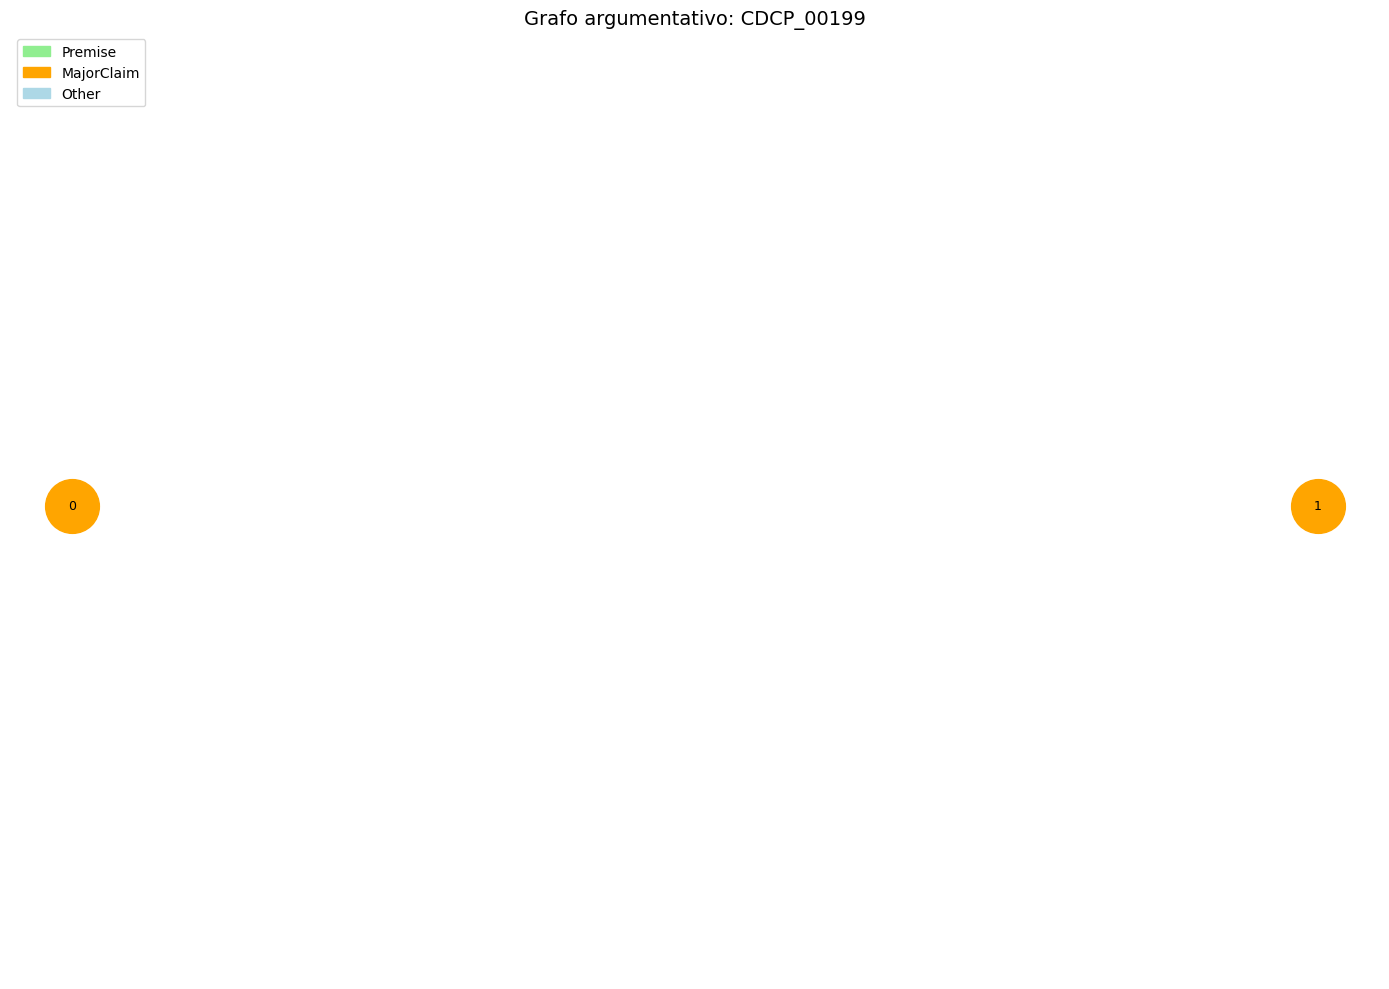

In [136]:
# plot_grafo(id_text_busca, result_info["graph"])
di_graph(id_text_busca, result_info["graph"])

## Estadisticas

In [18]:
def plot_estadisticas(df):
    bool_cols = ["is_acyclic", "is_connected", "is_tree", "is_arborescence", "is_forest"]
    num_cols  = ["n_nodes", "n_edges", "n_isolates", "n_comp", "n_root"]

    # Convertir a numérico
    df[num_cols] = df[num_cols].astype(int)
    # Convertir columnas booleanas a bool
    df[bool_cols] = df[bool_cols].astype(bool)

    resultado = (df[bool_cols].mean() * 100).round(2).reset_index()
    resultado.columns = ["Propiedad", "% True"]
    resultado["% True"] = resultado["% True"].astype(str)

    # Estadísticas
    print("=== Estadísticas ===")
    print(tabulate(df[num_cols].describe(), headers='keys', tablefmt='rounded_outline', showindex=True))
    print(tabulate(resultado, headers='keys', tablefmt='rounded_outline', showindex=False))

In [79]:
plot_estadisticas(df_comparacion)

=== Estadísticas ===
╭───────┬───────────┬───────────┬──────────────┬──────────┬──────────╮
│       │   n_nodes │   n_edges │   n_isolates │   n_comp │   n_root │
├───────┼───────────┼───────────┼──────────────┼──────────┼──────────┤
│ count │  70       │  70       │           70 │       70 │       70 │
│ mean  │   2.95714 │   1.95714 │            0 │        1 │        1 │
│ std   │   1.48846 │   1.48846 │            0 │        0 │        0 │
│ min   │   2       │   1       │            0 │        1 │        1 │
│ 25%   │   2       │   1       │            0 │        1 │        1 │
│ 50%   │   2.5     │   1.5     │            0 │        1 │        1 │
│ 75%   │   3       │   2       │            0 │        1 │        1 │
│ max   │  11       │  10       │            0 │        1 │        1 │
╰───────┴───────────┴───────────┴──────────────┴──────────┴──────────╯
╭─────────────────┬──────────╮
│ Propiedad       │   % True │
├─────────────────┼──────────┤
│ is_acyclic      │      100 │
│ i

/tmp/ipykernel_6817/1987421654.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df[num_cols] = df[num_cols].astype(int)
/tmp/ipykernel_6817/1987421654.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df[bool_cols] = df[bool_cols].astype(bool)


## Resumen comparativo de valores booleanos

/tmp/ipykernel_6817/3882363675.py:22: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  heatmap_data = df[bool_cols].applymap(extraer_porcentaje_true)


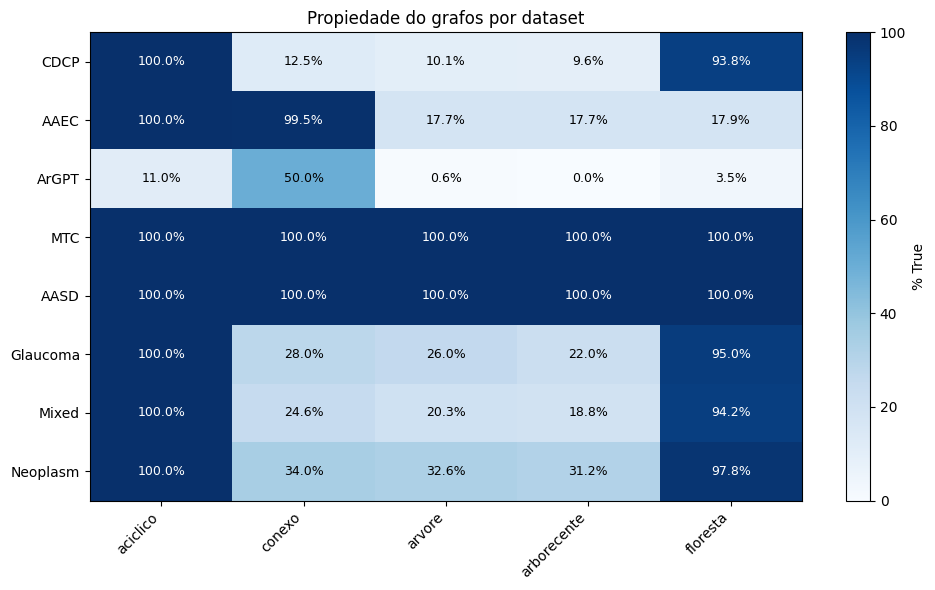

In [9]:
df = pd.read_pickle(result_path + "dataframe_summary.pkl")

bool_cols = ["is_acyclic", "is_connected", "is_tree", "is_arborescence", "is_forest"]

bool_cols = ["aciclico", "conexo", "arvore", "arborecente", "floresta"]

def extraer_porcentaje_true(valor):
    """Extrae el % de True de un string como '639: False, 91: True'"""
    total = 0
    true_count = 0
    for parte in str(valor).split(","):
        parte = parte.strip()
        count, estado = parte.split(":")
        count = int(count.strip())
        estado = estado.strip()
        total += count
        if estado == "True":
            true_count += count
    return (true_count / total) * 100

# Construir matriz para el heatmap
heatmap_data = df[bool_cols].applymap(extraer_porcentaje_true)

# Graficar
fig, ax = plt.subplots(figsize=(10, 6))

im = ax.imshow(heatmap_data.values, cmap="Blues", aspect="auto", vmin=0, vmax=100)

# Etiquetas ejes
ax.set_xticks(range(len(bool_cols)))
ax.set_xticklabels(bool_cols, rotation=45, ha="right", fontsize=10)
ax.set_yticks(range(len(heatmap_data)))
ax.set_yticklabels(heatmap_data.index, fontsize=10)

# Valores dentro de cada celda
for i in range(len(heatmap_data)):
    for j in range(len(bool_cols)):
        val = heatmap_data.iloc[i, j]
        color = "white" if val > 60 else "black"
        ax.text(j, i, f"{val:.1f}%", ha="center", va="center", fontsize=9, color=color)

plt.colorbar(im, ax=ax, label="% True")
plt.title("Propiedade do grafos por dataset")
plt.tight_layout()
plt.show()

## Comparação de Variáveis númericas por Dateset

In [109]:
# Cargar el DataFrame
datasets = {
    "CDCP":     "CDCP_Minimal_Grafo.pkl",
    "AAEC":     "AAEC_Minimal_Grafo.pkl",
    "ArGPT":    "ArGPT_Minimal_Grafo.pkl",
    "MTC":      "MTC_Minimal_Grafo.pkl",
    "AASD":     "AASD_Minimal_Grafo.pkl",
    "Glaucoma": "AbstRCT_glaucoma_Minimal_Grafo.pkl",
    "Mixed":    "AbstRCT_mixed_Minimal_Grafo.pkl",
    "Neoplasm": "AbstRCT_neoplasm_Minimal_Grafo.pkl",
}

dfs = []
for name, file in datasets.items():
    df = pd.read_pickle(result_path + file)
    df["dataset"] = name
    dfs.append(df)

df_all = pd.concat(dfs, ignore_index=True)

print(df_all.shape)
print(df_all["dataset"].value_counts())
df_all

(2145, 15)
dataset
CDCP        730
Neoplasm    500
AAEC        402
ArGPT       172
MTC         112
Glaucoma    100
Mixed        69
AASD         60
Name: count, dtype: int64


,text_id,seg,info,graph,n_nodes,n_edges,n_isolates,n_comp,n_root,is_acyclic,is_connected,is_tree,is_arborescence,is_forest,dataset
0,CDCP_00194,3,minimalist_labels labels_relation source...,"(CDCP_00194_0, CDCP_00194_1, CDCP_00194_2)",3,1,1,2,2,True,False,False,False,True,CDCP
1,CDCP_00195,3,minimalist_labels labels_relation source...,"(CDCP_00195_0, CDCP_00195_1, CDCP_00195_2)",3,2,0,1,1,True,True,True,True,True,CDCP
2,CDCP_00196,5,"Empty DataFrame Columns: [minimalist_labels, l...","(CDCP_00196_0, CDCP_00196_1, CDCP_00196_2, CDC...",5,0,5,5,5,True,False,False,False,True,CDCP
3,CDCP_00197,4,minimalist_labels labels_relation source...,"(CDCP_00197_0, CDCP_00197_1, CDCP_00197_2, CDC...",4,1,2,3,3,True,False,False,False,True,CDCP
4,CDCP_00198,4,minimalist_labels labels_relation source...,"(CDCP_00198_0, CDCP_00198_1, CDCP_00198_2, CDC...",4,1,2,3,3,True,False,False,False,True,CDCP
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2140,AbstRCT_neoplasm_9807987,5,minimalist_labels labels_relation ...,"(AbstRCT_neoplasm_9807987_0, AbstRCT_neoplasm_...",5,3,1,2,2,True,False,False,False,True,Neoplasm
2141,AbstRCT_neoplasm_9849452,9,minimalist_labels labels_relation ...,"(AbstRCT_neoplasm_9849452_0, AbstRCT_neoplasm_...",9,5,1,4,4,True,False,False,False,True,Neoplasm
2142,AbstRCT_neoplasm_9849454,6,minimalist_labels labels_relation ...,"(AbstRCT_neoplasm_9849454_0, AbstRCT_neoplasm_...",6,4,0,2,2,True,False,False,False,True,Neoplasm
2143,AbstRCT_neoplasm_9850014,6,minimalist_labels labels_relation ...,"(AbstRCT_neoplasm_9850014_0, AbstRCT_neoplasm_...",6,3,2,3,3,True,False,False,False,True,Neoplasm


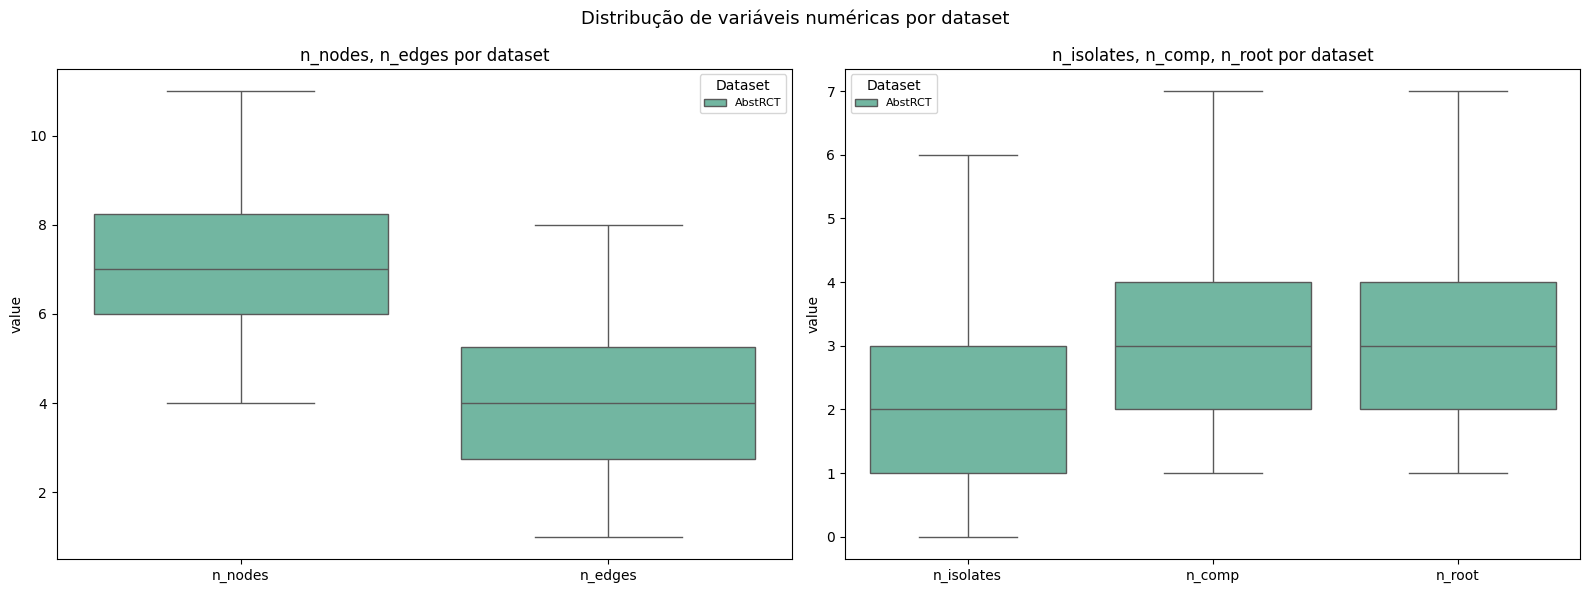

In [97]:
# 1. Cargamos la data
# df = df_all
df["dataset"] = df_comparacion["text_id"].apply(lambda x: x.split("_")[0])
# 2. Convertir a formato long
num_cols = ["n_nodes", "n_edges", "n_isolates", "n_comp", "n_root"]

df_long = df.melt(
    id_vars=["text_id", "dataset"],
    value_vars=num_cols,
    var_name="variable",
    value_name="value"
)

# 3. Separar en dos grupos por escala
grupo1 = ["n_nodes", "n_edges"]
grupo2 = ["n_isolates", "n_comp", "n_root"]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Grupo 1
sns.boxplot(
    data=df_long[df_long["variable"].isin(grupo1)],
    x="variable", y="value", hue="dataset",
    ax=axes[0], palette="Set2"
)
axes[0].set_title("n_nodes, n_edges por dataset")
axes[0].set_xlabel("")
axes[0].legend(title="Dataset", fontsize=8)

# Grupo 2
sns.boxplot(
    data=df_long[df_long["variable"].isin(grupo2)],
    x="variable", y="value", hue="dataset",
    ax=axes[1], palette="Set2"
)
axes[1].set_title("n_isolates, n_comp, n_root por dataset")
axes[1].set_xlabel("")
axes[1].legend(title="Dataset", fontsize=8)

plt.suptitle("Distribução de variáveis numéricas por dataset", fontsize=13)
plt.tight_layout()
plt.show()

In [141]:
# Verificar se o raiz do grafo é MajorClaim
def verificar_raices(G):
    raices = [n for n, d in G.in_degree() if d == 0]
    
    resultado = {}
    for nodo in raices:
        tipo = G.nodes[nodo].get("component", "unknown")
        is_major_claim = tipo == "MajorClaim"
        resultado[nodo] = {
            "tipo": tipo,
            "es_MajorClaim": is_major_claim
        }
    
    return resultado

data_raiz = {}
# df_all = df_comparacion
for idx, row in df_all.iterrows():
    data_raiz[row["text_id"]] = verificar_raices(row["graph"])
print(data_raiz)
# df_all.shape


{'CDCP_00194': {'CDCP_00194_0': {'tipo': 'Premise', 'es_MajorClaim': False}, 'CDCP_00194_2': {'tipo': 'MajorClaim', 'es_MajorClaim': True}}, 'CDCP_00195': {'CDCP_00195_2': {'tipo': 'MajorClaim', 'es_MajorClaim': True}}, 'CDCP_00196': {'CDCP_00196_0': {'tipo': 'Premise', 'es_MajorClaim': False}, 'CDCP_00196_1': {'tipo': 'MajorClaim', 'es_MajorClaim': True}, 'CDCP_00196_2': {'tipo': 'MajorClaim', 'es_MajorClaim': True}, 'CDCP_00196_3': {'tipo': 'MajorClaim', 'es_MajorClaim': True}, 'CDCP_00196_4': {'tipo': 'MajorClaim', 'es_MajorClaim': True}}, 'CDCP_00197': {'CDCP_00197_1': {'tipo': 'Premise', 'es_MajorClaim': False}, 'CDCP_00197_2': {'tipo': 'Premise', 'es_MajorClaim': False}, 'CDCP_00197_3': {'tipo': 'MajorClaim', 'es_MajorClaim': True}}, 'CDCP_00198': {'CDCP_00198_1': {'tipo': 'Premise', 'es_MajorClaim': False}, 'CDCP_00198_2': {'tipo': 'MajorClaim', 'es_MajorClaim': True}, 'CDCP_00198_3': {'tipo': 'MajorClaim', 'es_MajorClaim': True}}, 'CDCP_00199': {'CDCP_00199_0': {'tipo': 'MajorC

In [143]:
# Lista de datasets conocidos
DATASETS = ["CDCP", "AAEC", "ArGPT", "MTC", "AASD", "AbstRCT_glaucoma", "AbstRCT_mixed", "AbstRCT_neoplasm"]

def extraer_dataset(text_id):
    for dataset in DATASETS:
        if text_id.startswith(dataset):
            return dataset
    return "unknown"

def filtrar_sin_major(diccionario):
    resultado = {}
    
    for text_id, raices in diccionario.items():
        # sin_major = not any(info["es_MajorClaim"] for info in raices.values())
        sin_major = any(info["es_MajorClaim"] for info in raices.values())
        
        if sin_major:
            resultado[text_id] = raices
    
    return resultado

def resumen_por_dataset(problemas):
    resumen = defaultdict(int)
    
    for text_id in problemas.keys():
        dataset = extraer_dataset(text_id)
        resumen[dataset] += 1
    
    return dict(resumen)

In [148]:
problemas = filtrar_sin_major(data_raiz)
resumen = resumen_por_dataset(problemas)

print(f"Total grafos sin MajorClaim: {len(problemas)}")
for dataset, cantidad in resumen.items():
    print(f"{dataset}: {cantidad} grafos")

for text_id, raices in problemas.items():
    print(f"\n{text_id}")
    for nodo, info in raices.items():
        print(f"  {nodo} → {info['tipo']}")

Total grafos sin MajorClaim: 1393
CDCP: 682 grafos
AAEC: 402 grafos
ArGPT: 24 grafos
MTC: 112 grafos
AASD: 60 grafos
AbstRCT_glaucoma: 6 grafos
AbstRCT_mixed: 27 grafos
AbstRCT_neoplasm: 80 grafos

CDCP_00194
  CDCP_00194_0 → Premise
  CDCP_00194_2 → MajorClaim

CDCP_00195
  CDCP_00195_2 → MajorClaim

CDCP_00196
  CDCP_00196_0 → Premise
  CDCP_00196_1 → MajorClaim
  CDCP_00196_2 → MajorClaim
  CDCP_00196_3 → MajorClaim
  CDCP_00196_4 → MajorClaim

CDCP_00197
  CDCP_00197_1 → Premise
  CDCP_00197_2 → Premise
  CDCP_00197_3 → MajorClaim

CDCP_00198
  CDCP_00198_1 → Premise
  CDCP_00198_2 → MajorClaim
  CDCP_00198_3 → MajorClaim

CDCP_00199
  CDCP_00199_0 → MajorClaim
  CDCP_00199_1 → MajorClaim

CDCP_00200
  CDCP_00200_1 → MajorClaim

CDCP_00201
  CDCP_00201_0 → Premise
  CDCP_00201_1 → MajorClaim
  CDCP_00201_2 → Premise
  CDCP_00201_4 → Premise
  CDCP_00201_5 → Premise
  CDCP_00201_7 → Premise
  CDCP_00201_8 → Premise

CDCP_00203
  CDCP_00203_1 → MajorClaim

CDCP_00204
  CDCP_00204_1 →

In [ ]:
# Cuantos nodos raiz son Major Claim
problemas = filtrar_sin_major(data_raiz)
resumen = defaultdict(int)
for instancia, componentes in problemas.items():  
    majorclaims = [comp for comp, datos in componentes.items() if datos['es_MajorClaim']]
    cantidad = len(majorclaims)
    if cantidad == 2:
        dataset = extraer_dataset(instancia)
        if dataset == 'AbstRCT_glaucoma':
            print(f"{instancia}: {cantidad} MajorClaims → {majorclaims}")
        resumen[dataset] += 1
    # elif cantidad == 1:
    #     print(f"✓  {instancia}: 1 MajorClaim  → {majorclaims[0]}")
    # else:
        # print(f"✗  {instancia}: sin MajorClaim")
result = dict(resumen)
for dataset, cantidad in result.items():
    print(f"{dataset}: {cantidad} grafos")


CDCP: 184 grafos
AAEC: 313 grafos
AbstRCT_glaucoma: 1 grafos
AbstRCT_mixed: 2 grafos
AbstRCT_neoplasm: 9 grafos


In [131]:
df_key = df[df[columna].isin(problemas.keys())]

df_key = df_key[
    (df_key["is_arborescence"] == False)
    &
    (df_key["n_nodes"] == 7)
]
df_key

,text_id,seg,info,graph,n_nodes,n_edges,n_isolates,n_comp,n_root,is_acyclic,is_connected,is_tree,is_arborescence,is_forest
40,CDCP_00314,7,"Empty DataFrame Columns: [minimalist_labels, l...","(CDCP_00314_0, CDCP_00314_1, CDCP_00314_2, CDC...",7,0,7,7,7,True,False,False,False,True
50,CDCP_00332,7,minimalist_labels labels_relation source...,"(CDCP_00332_0, CDCP_00332_1, CDCP_00332_2, CDC...",7,1,5,6,6,True,False,False,False,True
56,CDCP_00338,7,minimalist_labels labels_relation source...,"(CDCP_00338_0, CDCP_00338_1, CDCP_00338_2, CDC...",7,4,1,3,4,True,False,False,False,True
109,CDCP_00400,7,minimalist_labels labels_relation source...,"(CDCP_00400_0, CDCP_00400_1, CDCP_00400_2, CDC...",7,7,0,1,2,True,True,False,False,False
119,CDCP_00413,7,minimalist_labels labels_relation source...,"(CDCP_00413_0, CDCP_00413_1, CDCP_00413_2, CDC...",7,2,4,5,5,True,False,False,False,True
126,CDCP_00423,7,minimalist_labels labels_relation source...,"(CDCP_00423_0, CDCP_00423_1, CDCP_00423_2, CDC...",7,4,1,3,3,True,False,False,False,True
127,CDCP_00424,7,minimalist_labels labels_relation source...,"(CDCP_00424_0, CDCP_00424_1, CDCP_00424_2, CDC...",7,2,3,5,5,True,False,False,False,True
136,CDCP_00436,7,minimalist_labels labels_relation source...,"(CDCP_00436_0, CDCP_00436_1, CDCP_00436_2, CDC...",7,1,5,6,6,True,False,False,False,True
183,CDCP_00513,7,minimalist_labels labels_relation source...,"(CDCP_00513_0, CDCP_00513_1, CDCP_00513_2, CDC...",7,1,5,6,6,True,False,False,False,True
193,CDCP_00526,7,minimalist_labels labels_relation source...,"(CDCP_00526_0, CDCP_00526_1, CDCP_00526_2, CDC...",7,4,3,4,5,True,False,False,False,False


In [117]:
id_text_busca = "CDCP_00196"
result_filt = df_key[df_key[columna] == id_text_busca].iloc[0]
di_graph(id_text_busca, result_filt["graph"])

IndexError: single positional indexer is out-of-bounds